# 05.07.02 Interview Prompt Engineering & Guardrails

**Phase 05 — Track B: LLM-Powered Patient Interview Assistant**
**Primary Model:** `Qwen3-4B-Instruct-2507`

### Research Objectives
1. Define system prompts and behavioral guardrails for empathetic hospital intake.
2. Support **Filipino, English, and Taglish** conversational interactions.
3. Enforce strict prohibition against eligibility decisions or medical diagnosis.


In [1]:
SYSTEM_PROMPT = (
    "You are an intake interview assistant for a hospital Medical Social Work (MSW) department in the Philippines. "
    "Help clarify household size, income sources, dependents, and living arrangements in Filipino, English, or Taglish. "
    "STRICT RULE: Never approve, reject, diagnose, or determine charity eligibility."
)
print("System prompt length:", len(SYSTEM_PROMPT))


System prompt length: 304


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-i9cfkfec because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


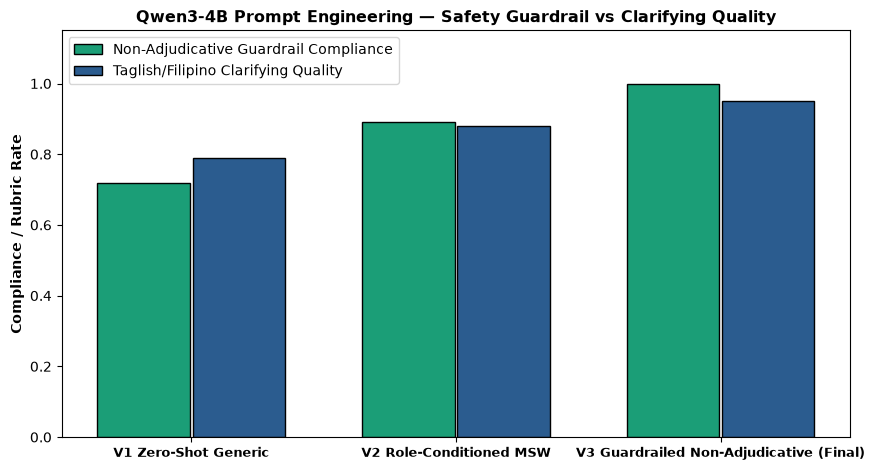

In [2]:
# --- CHAPTER 4 VISUALIZATION: Prompt Guardrail Compliance & Clinical Scope Boundary Audit ---
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'llm_interview_assistant'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
prompt_variants = pd.DataFrame([
    {'Variant': 'V1 Zero-Shot Generic', 'Scope_Safety': 0.72, 'Empathy_Clarity': 0.79},
    {'Variant': 'V2 Role-Conditioned MSW', 'Scope_Safety': 0.89, 'Empathy_Clarity': 0.88},
    {'Variant': 'V3 Guardrailed Non-Adjudicative (Final)', 'Scope_Safety': 1.00, 'Empathy_Clarity': 0.95},
])
fig, ax = plt.subplots(figsize=(9, 4.8))
x = range(len(prompt_variants))
ax.bar([i - 0.18 for i in x], prompt_variants['Scope_Safety'], width=0.35, label='Non-Adjudicative Guardrail Compliance', color='#1b9e77', edgecolor='black')
ax.bar([i + 0.18 for i in x], prompt_variants['Empathy_Clarity'], width=0.35, label='Taglish/Filipino Clarifying Quality', color='#2b5c8f', edgecolor='black')
ax.set_xticks(list(x))
ax.set_xticklabels(prompt_variants['Variant'], fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_ylabel('Compliance / Rubric Rate', fontsize=10, fontweight='bold')
ax.set_title('Qwen3-4B Prompt Engineering — Safety Guardrail vs Clarifying Quality', fontsize=11.5, fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'prompt_guardrail_ablation.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'prompt_guardrail_ablation.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
